# Лабораторная работа №1
Набор данных: `python_learning_exam_performance.csv` — результаты изучения Python и итогового экзамена. Целевая переменная `passed_exam` содержит два класса: экзамен сдан (`1`) или не сдан (`0`). 

Признаки датасета:
- `age` — возраст студента;
- `country` — страна;
- `prior_programming_experience` — предыдущий опыт программирования;
- `weeks_in_course` — количество недель обучения;
- `hours_spent_learning_per_week` — часов обучения в неделю;
- `practice_problems_solved` — решённые практические задачи;
- `projects_completed` — завершённые проекты;
- `tutorial_videos_watched` — просмотренные обучающие видео;
- `uses_kaggle` — использование Kaggle;
- `participates_in_discussion_forums` — участие в форумах;
- `debugging_sessions_per_week` — сеансы отладки в неделю;
- `self_reported_confidence_python` — самооценка знания Python;
- `final_exam_score` — итоговый балл;
- `passed_exam` — целевой класс.

`student_id` исключается как идентификатор.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [2]:
df = pd.read_csv('python_learning_exam_performance.csv')
df.head()

,student_id,age,country,prior_programming_experience,weeks_in_course,hours_spent_learning_per_week,practice_problems_solved,projects_completed,tutorial_videos_watched,uses_kaggle,participates_in_discussion_forums,debugging_sessions_per_week,self_reported_confidence_python,final_exam_score,passed_exam
0,1,54,Pakistan,Beginner,12,12.2,60,1,24,0,1,4,10,53.8,0
1,2,44,Nigeria,NaN,15,14.2,52,1,32,0,0,5,7,31.9,0
2,3,30,India,Intermediate,5,7.7,71,1,43,0,0,6,3,59.4,0
3,4,23,Nigeria,Beginner,4,5.6,64,2,40,1,0,3,10,58.8,0
4,5,36,UK,NaN,3,3.5,62,1,47,1,0,3,7,24.8,0


In [3]:
df.info()
display(df.describe(include='all').T)
print('Количество пропусков:')
display(df.isna().sum())
print('Распределение классов:')
display(df['passed_exam'].value_counts().sort_index())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 15 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   student_id                         3000 non-null   int64  
 1   age                                3000 non-null   int64  
 2   country                            3000 non-null   object 
 3   prior_programming_experience       1938 non-null   object 
 4   weeks_in_course                    3000 non-null   int64  
 5   hours_spent_learning_per_week      3000 non-null   float64
 6   practice_problems_solved           3000 non-null   int64  
 7   projects_completed                 3000 non-null   int64  
 8   tutorial_videos_watched            3000 non-null   int64  
 9   uses_kaggle                        3000 non-null   int64  
 10  participates_in_discussion_forums  3000 non-null   int64  
 11  debugging_sessions_per_week        3000 non-null   int64

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
student_id,3000.0,NaN,NaN,NaN,1500.5,866.169729,1.0,750.75,1500.5,2250.25,3000.0
age,3000.0,NaN,NaN,NaN,35.327,11.302182,16.0,26.0,36.0,45.0,54.0
country,3000,10,Brazil,339,NaN,NaN,NaN,NaN,NaN,NaN,NaN
prior_programming_experience,1938,3,Beginner,1034,NaN,NaN,NaN,NaN,NaN,NaN,NaN
weeks_in_course,3000.0,NaN,NaN,NaN,8.121,4.275019,1.0,5.0,8.0,12.0,15.0
hours_spent_learning_per_week,3000.0,NaN,NaN,NaN,7.035267,2.936134,0.0,5.0,7.0,9.0,17.1
practice_problems_solved,3000.0,NaN,NaN,NaN,59.983667,7.713056,35.0,55.0,60.0,65.0,87.0
projects_completed,3000.0,NaN,NaN,NaN,2.001333,1.395701,0.0,1.0,2.0,3.0,9.0
tutorial_videos_watched,3000.0,NaN,NaN,NaN,39.896667,6.263258,19.0,35.0,40.0,44.0,63.0
uses_kaggle,3000.0,NaN,NaN,NaN,0.400667,0.490115,0.0,0.0,0.0,1.0,1.0


Количество пропусков:


student_id                              0
age                                     0
country                                 0
prior_programming_experience         1062
weeks_in_course                         0
hours_spent_learning_per_week           0
practice_problems_solved                0
projects_completed                      0
tutorial_videos_watched                 0
uses_kaggle                             0
participates_in_discussion_forums       0
debugging_sessions_per_week             0
self_reported_confidence_python         0
final_exam_score                        0
passed_exam                             0
dtype: int64

Распределение классов:


passed_exam
0    2468
1     532
Name: count, dtype: int64

Уменьшим датасет пропорционально исходному распределению классов. Это ускоряет ресурсоёмкие t-SNE, UMAP, MDS и Isomap, сохраняя дисбаланс исходных данных.

In [4]:
target_size = 1200
classes = df['passed_exam'].unique()
sampled_dfs = []

for cls in classes:
    cls_df = df[df['passed_exam'] == cls]
    n_samples = max(1, int(len(cls_df) / len(df) * target_size))
    sampled_dfs.append(cls_df.sample(n=n_samples, random_state=42))

df = pd.concat(sampled_dfs).reset_index(drop=True)
print('Размер уменьшенной выборки:', df.shape)
df['passed_exam'].value_counts().sort_index()

Размер уменьшенной выборки: (1199, 15)


passed_exam
0    987
1    212
Name: count, dtype: int64

## Подготовка данных

In [ ]:
X = df.drop(columns=['student_id', 'passed_exam']).copy()
y = df['passed_exam'].copy()

# Пропуски опыта программирования обозначаем отдельной категорией
X['prior_programming_experience'] = X['prior_programming_experience'].fillna('Unknown')

In [ ]:
# Кодируем категориальные признаки
from sklearn.preprocessing import LabelEncoder, OrdinalEncoder

categorical_columns = X.select_dtypes(include='object').columns.tolist()
feature_encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
X[categorical_columns] = feature_encoder.fit_transform(X[categorical_columns])

# Используем LabelEncoder для целевой переменной
target_encoder = LabelEncoder()
y_encoded = target_encoder.fit_transform(y)
print('Классы:', dict(enumerate(target_encoder.classes_)))
X.head()

Классы: {0: 0, 1: 1}


,age,country,prior_programming_experience,weeks_in_course,hours_spent_learning_per_week,practice_problems_solved,projects_completed,tutorial_videos_watched,uses_kaggle,participates_in_discussion_forums,debugging_sessions_per_week,self_reported_confidence_python,final_exam_score
0,43,1.0,2.0,11,0.4,61,0,35,1,0,11,3,29.6
1,34,9.0,3.0,7,9.5,59,3,25,0,0,6,1,13.5
2,50,4.0,1.0,9,2.3,66,2,32,0,0,10,10,57.7
3,41,2.0,1.0,4,4.5,43,3,37,1,0,6,8,42.8
4,25,2.0,3.0,11,1.4,50,2,34,1,0,4,2,8.8


In [7]:
# Стандартизация
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled = pd.DataFrame(X_scaled, columns=X.columns)
X_scaled.head()

,age,country,prior_programming_experience,weeks_in_course,hours_spent_learning_per_week,practice_problems_solved,projects_completed,tutorial_videos_watched,uses_kaggle,participates_in_discussion_forums,debugging_sessions_per_week,self_reported_confidence_python,final_exam_score
0,0.720275,-1.207006,0.151790,0.715372,-2.257970,0.140470,-1.438453,-0.800101,1.236744,-0.997501,2.660952,-0.882031,-0.792569
1,-0.079940,1.553510,1.125033,-0.227708,0.843534,-0.117848,0.669989,-2.460400,-0.808575,-0.997501,0.453617,-1.575965,-1.716394
2,1.342665,-0.171813,-0.821452,0.243832,-1.610403,0.786264,-0.032825,-1.298190,-0.808575,-0.997501,2.219485,1.546738,0.819823
3,0.542450,-0.861942,-0.821452,-0.935018,-0.860589,-2.184390,0.669989,-0.468041,1.236744,-0.997501,0.453617,0.852804,-0.035146
4,-0.880155,-0.861942,1.125033,0.715372,-1.917145,-1.280278,-0.032825,-0.966131,1.236744,-0.997501,-0.429316,-1.228998,-1.986083


## Базовая визуализация: heatmap и распределения

In [8]:
corr = X_scaled.corr()
plt.figure(figsize=(14, 11))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Матрица корреляций')
plt.tight_layout()
plt.show()

C:\Users\1\AppData\Local\Temp\ipykernel_21164\806727172.py:6: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [9]:
X_scaled.hist(figsize=(16, 14), bins=25)
plt.suptitle('Распределения стандартизированных признаков', y=1.01)
plt.tight_layout()
plt.show()

C:\Users\1\AppData\Local\Temp\ipykernel_21164\1323131009.py:4: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## Запуск исходного класса многомерной визуализации

In [10]:
X_np = X_scaled.values
y_np = y_encoded
feature_names = X_scaled.columns.tolist()

print('Информация о данных:')
print('  Размер:', X_np.shape)
print('  Количество классов:', len(np.unique(y_np)))
print('  Количество признаков:', X_np.shape[1])
print('  Минимум:', X_np.min(), 'Максимум:', X_np.max())
print('  Среднее:', X_np.mean(), 'Стандартное отклонение:', X_np.std())

Информация о данных:
  Размер: (1199, 13)
  Количество классов: 2
  Количество признаков: 13
  Минимум: -3.2176611956475423 Максимум: 4.886871550129393
  Среднее: 1.641081573578213e-17 Стандартное отклонение: 1.0


ПОЛНАЯ ВИЗУАЛИЗАЦИЯ МНОГОМЕРНЫХ ДАННЫХ

1. Парные диаграммы рассеяния (PairPlot)


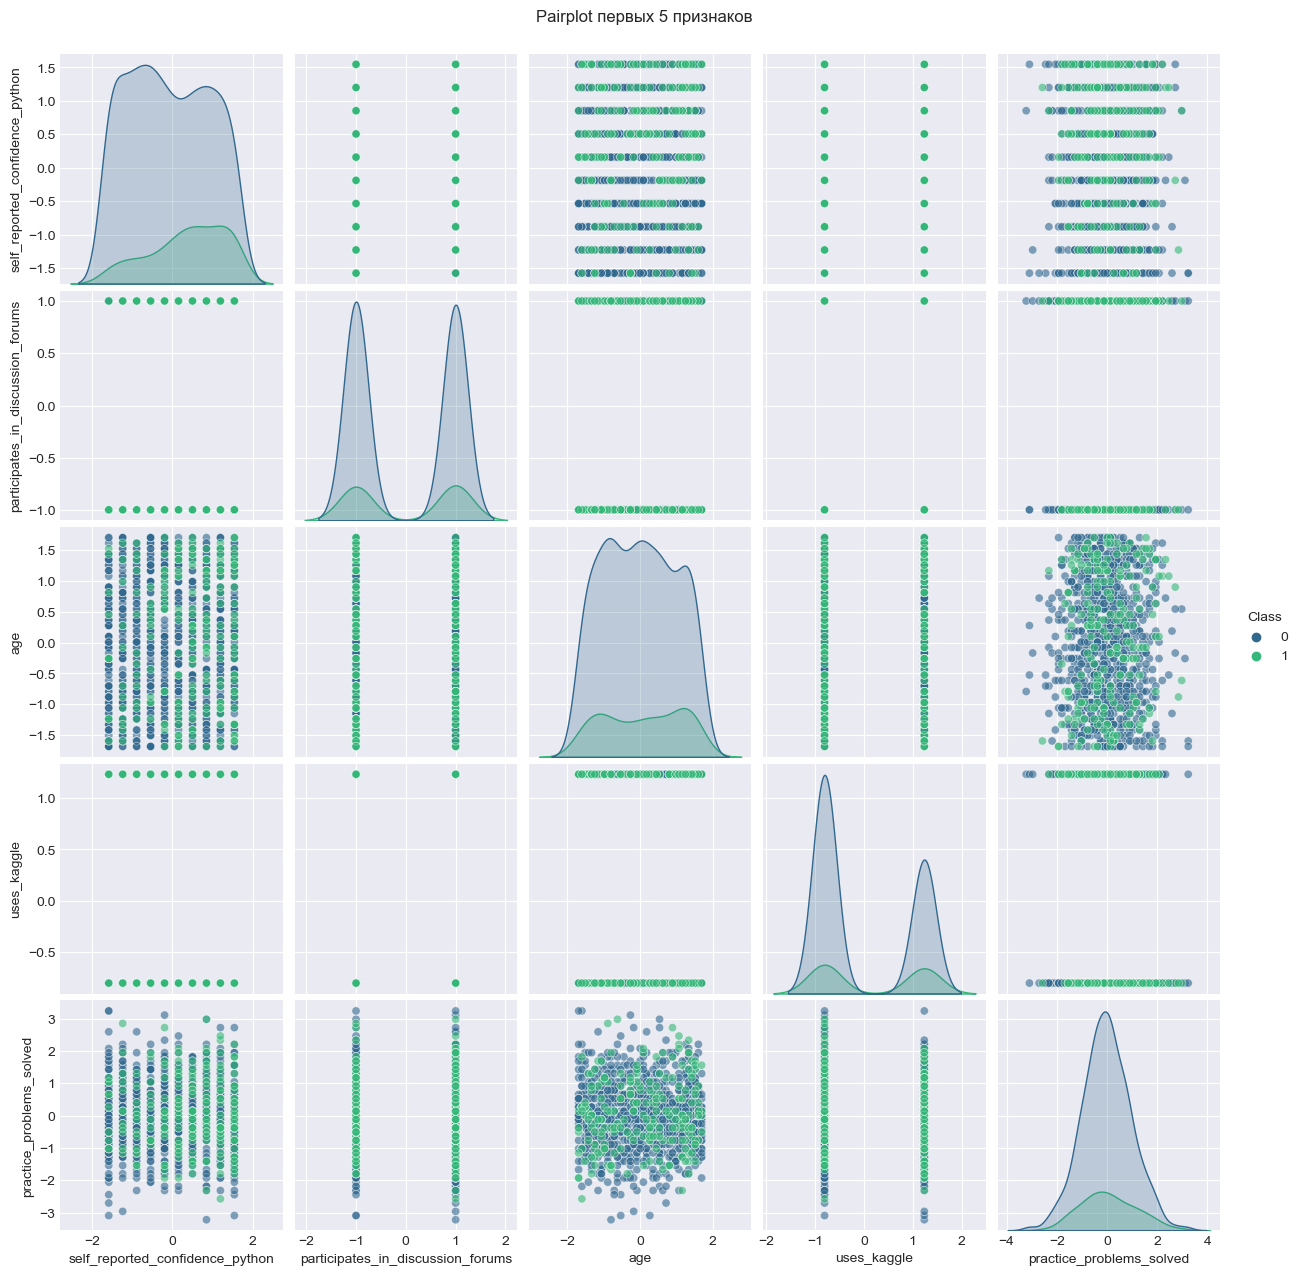


2. Тепловая карта корреляций


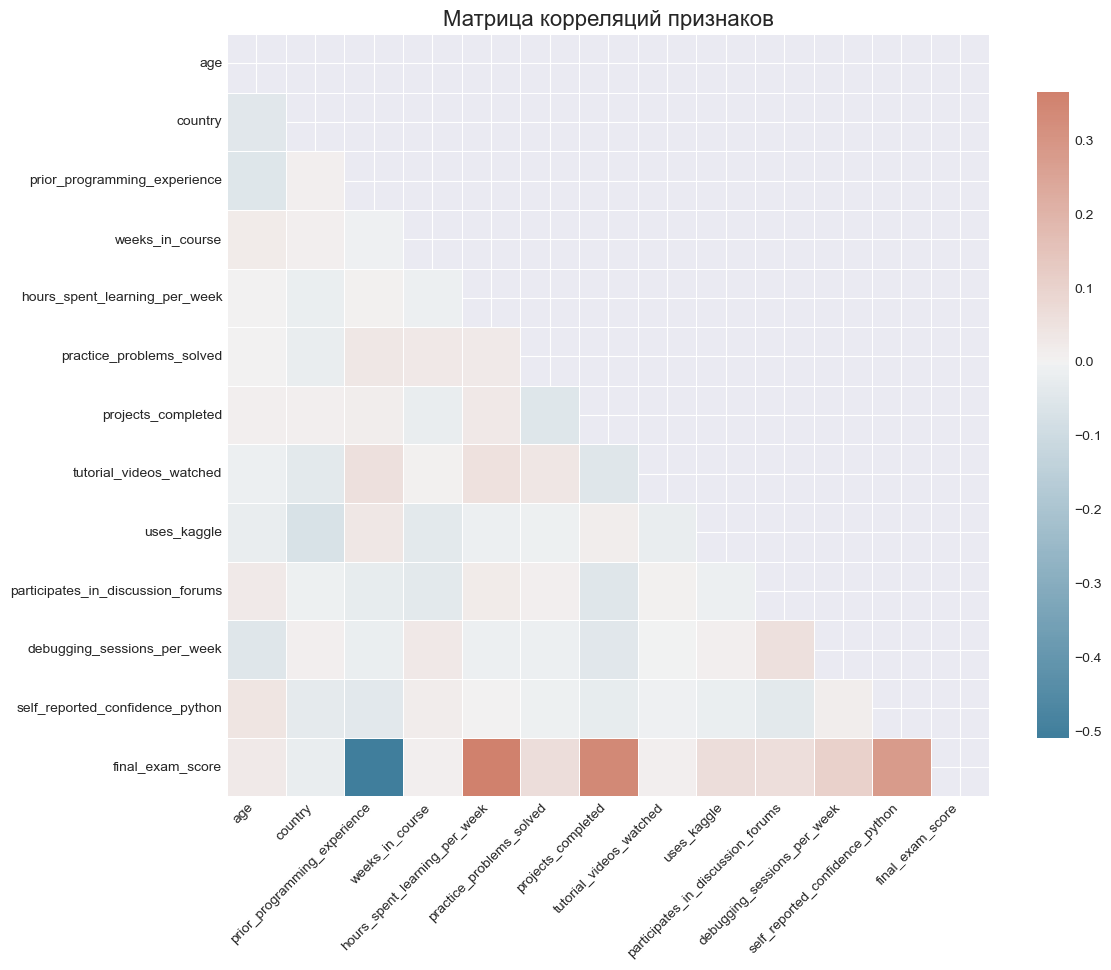


3. Визуализация PCA (2D и 3D)
Объясненная дисперсия: [0.13739292 0.08782111 0.08634363]
Суммарная объясненная дисперсия: 0.312


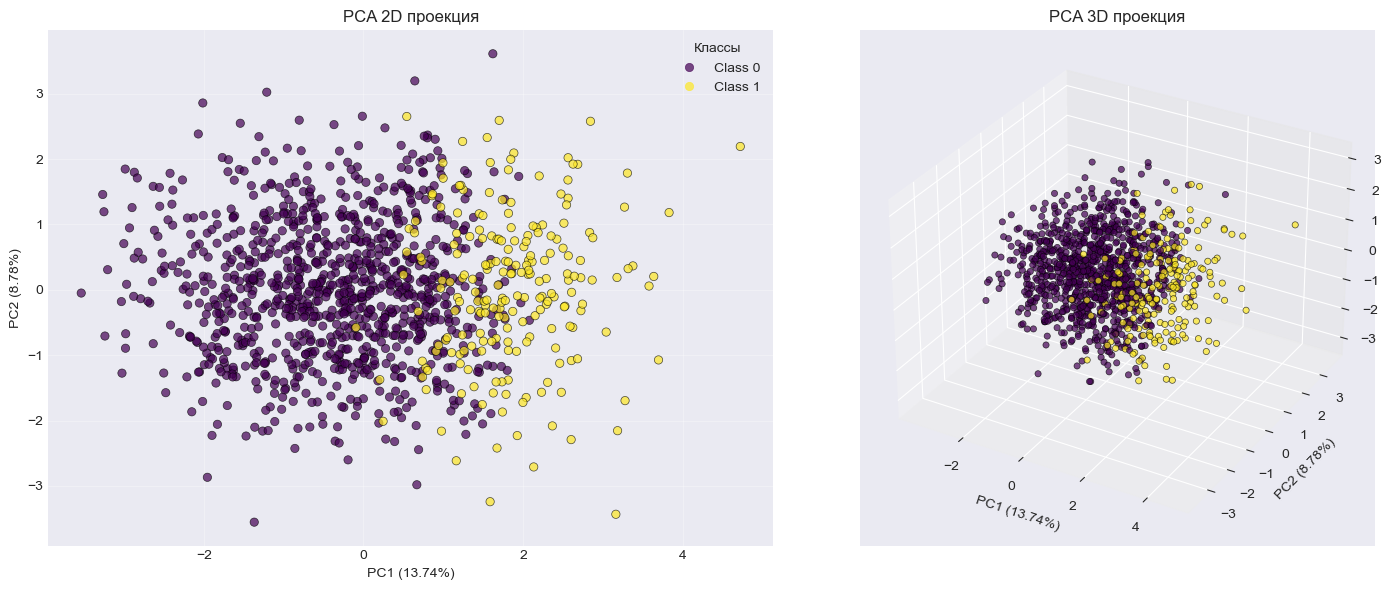

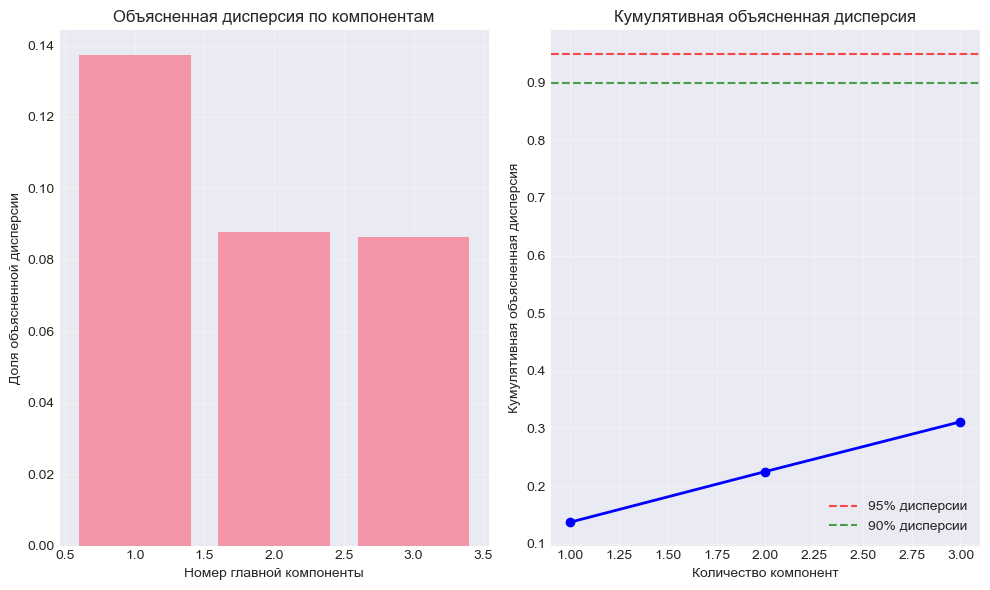


4. Визуализация t-SNE
  Применяем PCA для уменьшения размерности перед t-SNE...


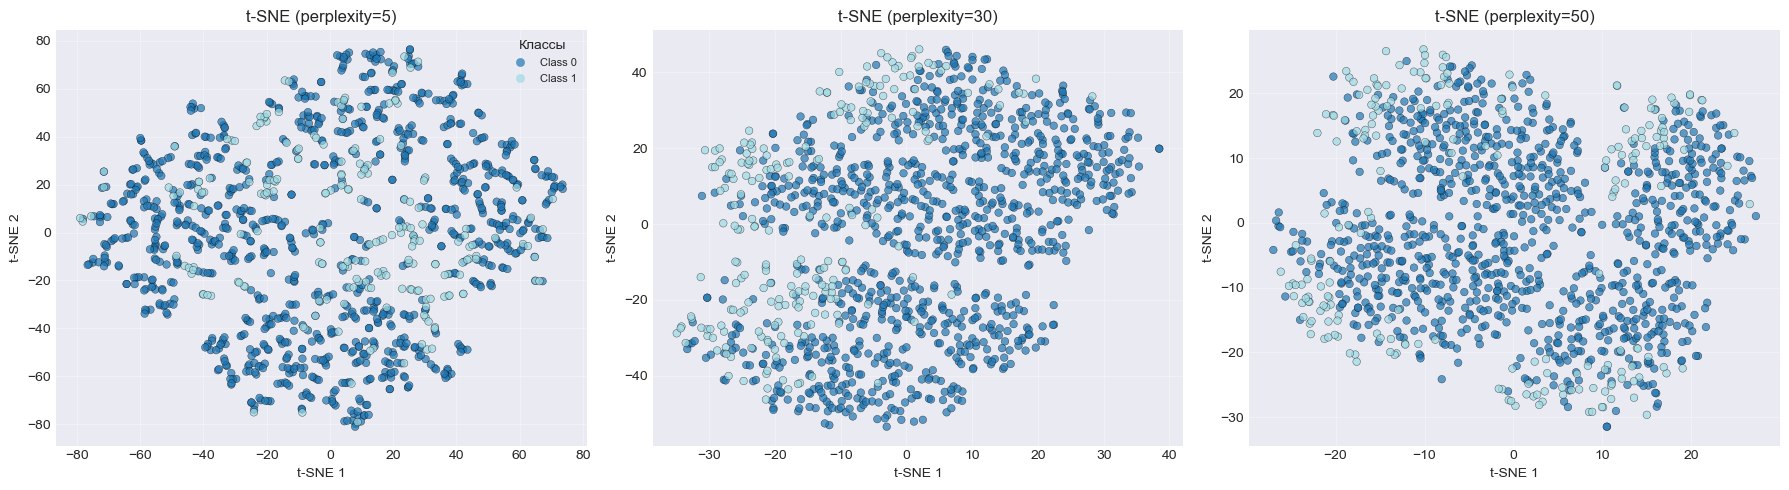


6. Параллельные координаты


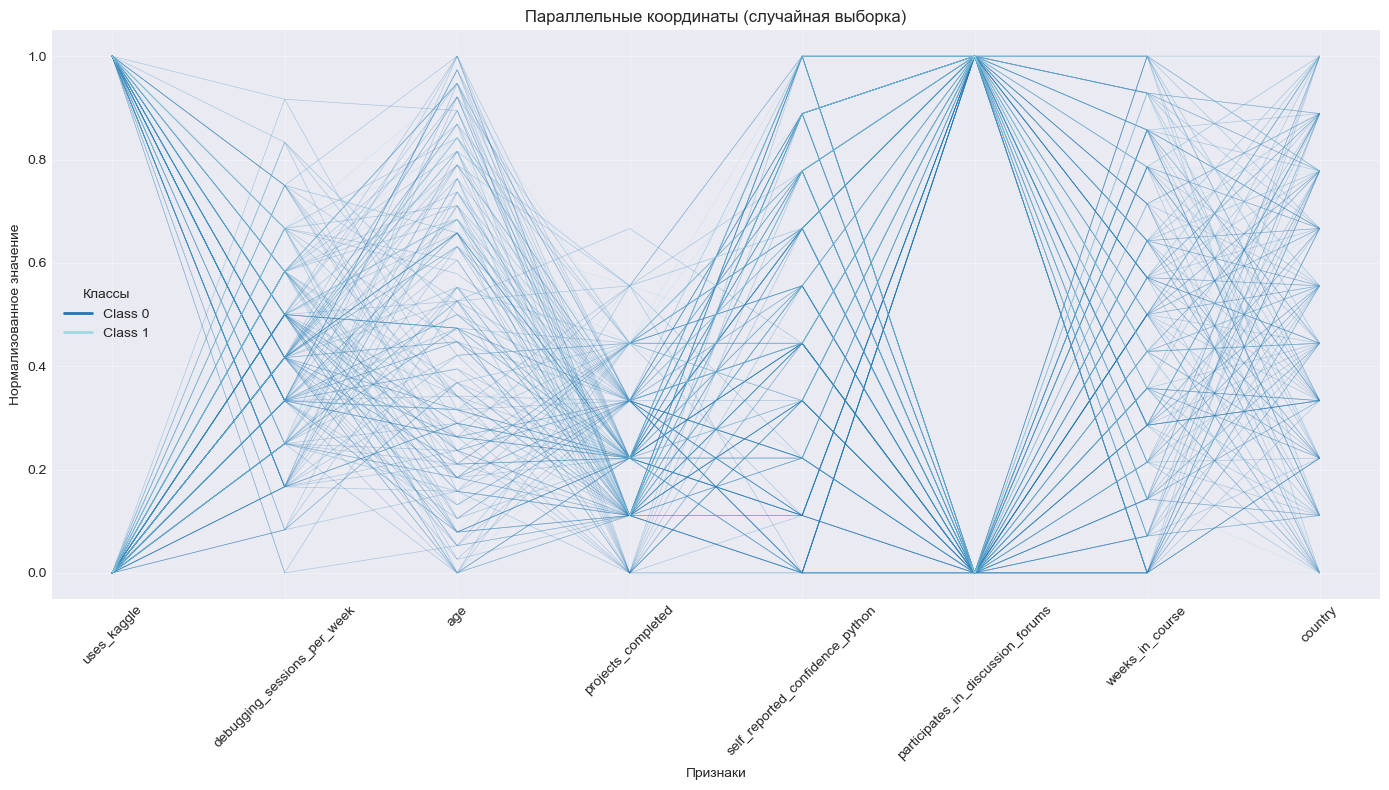


7. Радар-чарты по классам


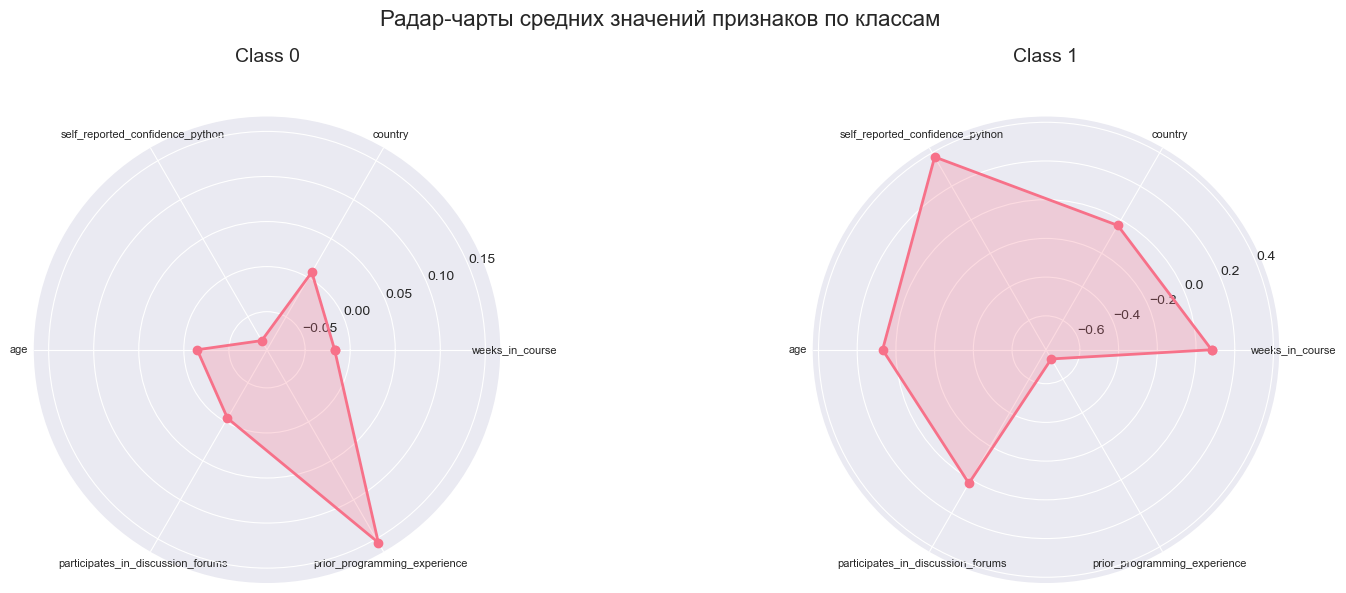


9. Сравнение методов уменьшения размерности
  Применяем PCA...
  Применяем t-SNE...
  Применяем MDS...
  Применяем Isomap...


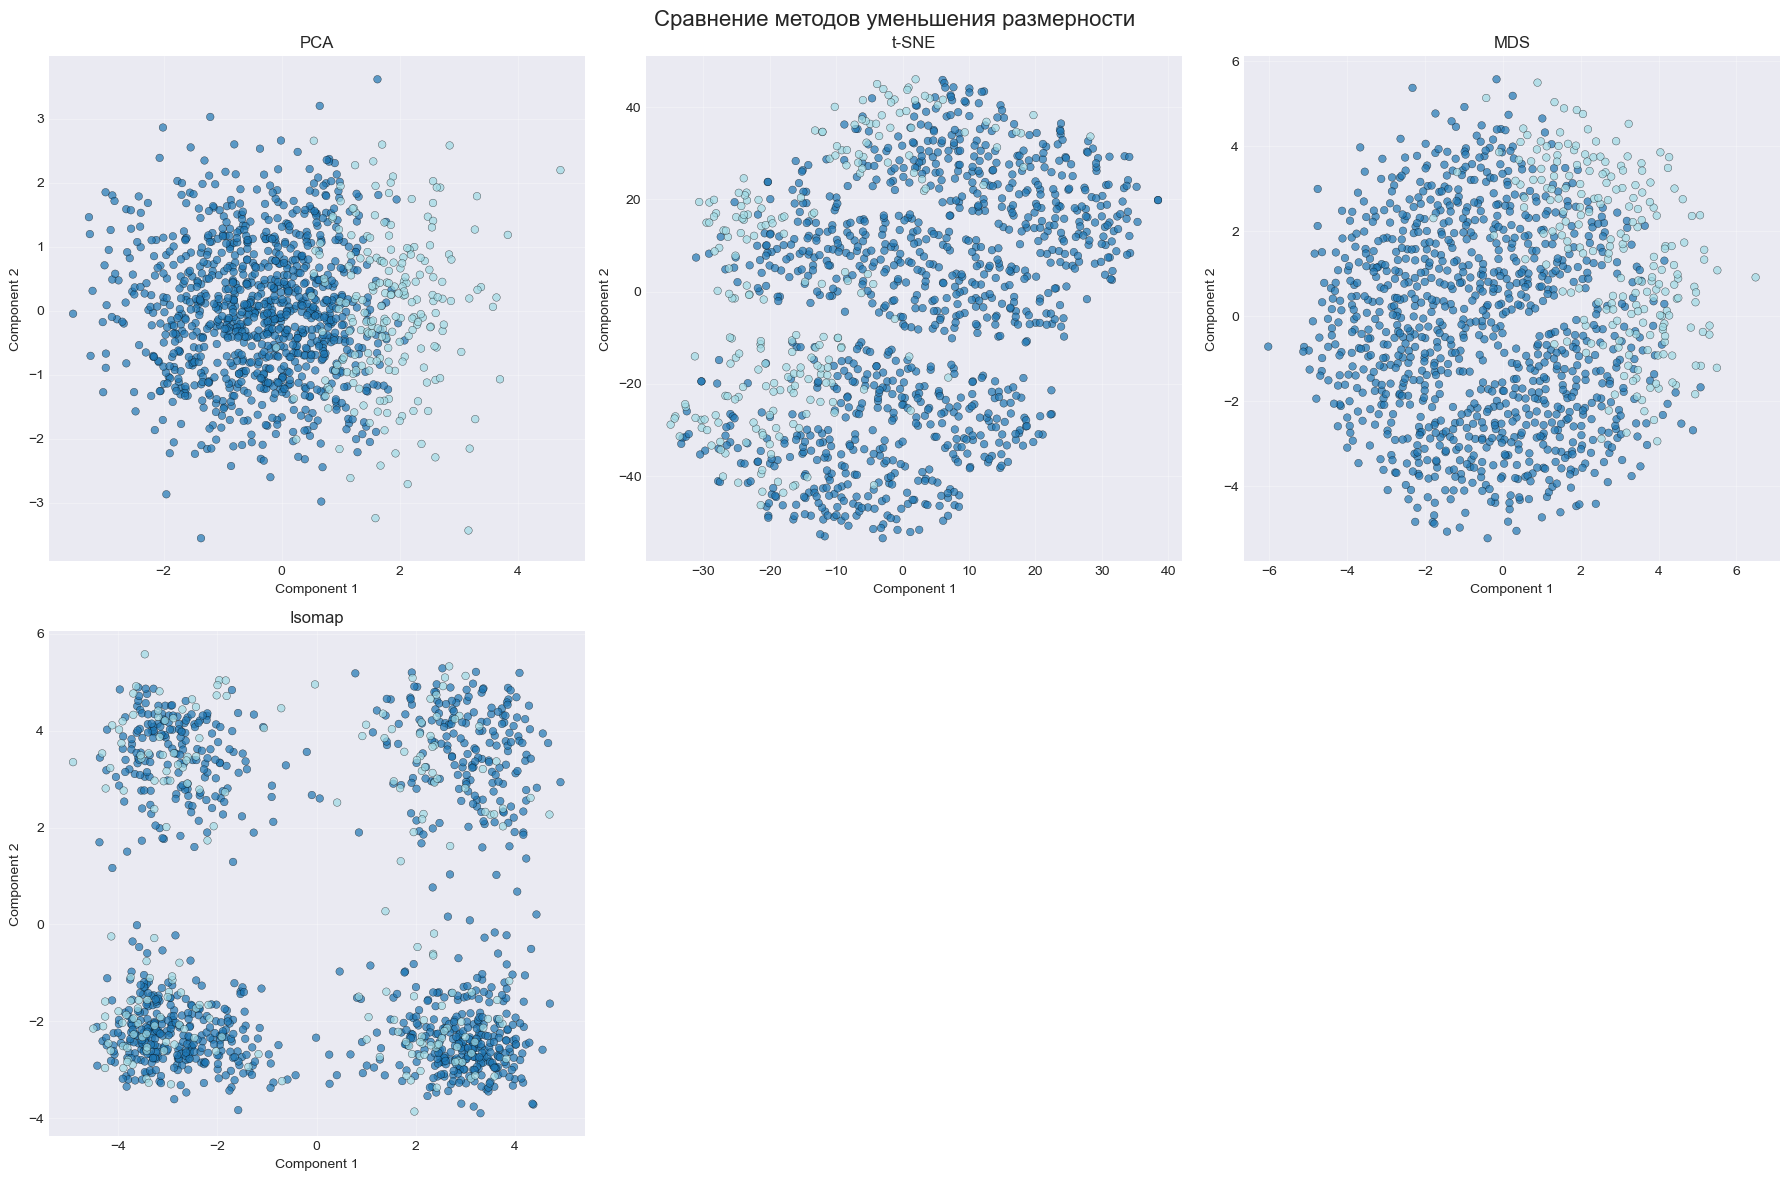


Примечание: Для UMAP визуализации установите: pip install umap-learn

8. Интерактивная 3D визуализация (откроется в браузере)
  График сохранен в файл: interactive_3d_plot.html



ВИЗУАЛИЗАЦИЯ ЗАВЕРШЕНА


In [41]:
# Перезагружаем локальный модуль, чтобы Jupyter не использовал старую версию из кэша
import importlib
import multidim_visualisation
importlib.reload(multidim_visualisation)

visualizer = multidim_visualisation.HighDimVisualizer(random_state=42)
visualizer.run_full_visualization(X_np, y_np, feature_names)